# **Task 5 — MAE**: where does a masked autoencoder keep what it learns?

This week's seminar was about [MAE](https://openaccess.thecvf.com/content/CVPR2022/html/He_Masked_Autoencoders_Are_Scalable_Vision_Learners_CVPR_2022_paper.html). It hides most patches of an image and trains an encoder and a small decoder to rebuild the missing pixels. Afterwards the decoder is thrown away and the encoder's features are used for recognition.

This notebook gives you CIFAR-10, the tiny ViT from Task 4, a **working MAE loop** and a **fixed evaluation**. The task is on the card.

<details>
<summary>Reach out here if you have any problems</summary>
Taras Kutsyk — taras.kutsyk@doctoral.uj.edu.pl
</details>

# Setup

**Step 0.** Runtime → Change runtime type → **T4 GPU**. Everything we need is already installed on Colab.

**Step 1. Data** (about 15 seconds). CIFAR-10: 50,000 training and 10,000 test images, 32×32, 10 classes, all kept on the GPU. **The labels are used only inside `knn_eval()` and `val_knn()`.**

In [ ]:
import io, time
import numpy as np, pandas as pd, requests, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "Switch to a GPU runtime: Runtime -> Change runtime type -> T4 GPU"

def load(split):
    # returns: images (N, 3, 32, 32) as floats in [0, 1], labels (N), both on the GPU
    url = f"https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{split}-00000-of-00001.parquet"
    response = requests.get(url, timeout=120); response.raise_for_status()
    table = pd.read_parquet(io.BytesIO(response.content))
    images = np.stack([np.asarray(Image.open(io.BytesIO(row["bytes"])).convert("RGB")) for row in table["img"]])
    return torch.from_numpy(images).permute(0, 3, 1, 2).float().div(255).to(device), torch.tensor(table["label"].values).to(device)

train_images, train_labels = load("train")
test_images, test_labels = load("test")

MEAN = torch.tensor([.4914, .4822, .4465], device=device)[None, :, None, None]
STD = torch.tensor([.2470, .2435, .2616], device=device)[None, :, None, None]
normalize = lambda x: (x - MEAN) / STD   # apply to every image before it enters the network

print("train", train_images.shape, "test", test_images.shape)

train torch.Size([50000, 3, 32, 32]) test torch.Size([10000, 3, 32, 32])


**Step 2. The encoder** (DON'T modify it). The same tiny ViT as in Task 4: 4×4 patches, so 8×8 = 64 patches + the CLS token; 4 blocks, 128 dimensions, 4 heads, 0.8M parameters.

One addition for MAE: `encode(x, keep, block)` can run the network on **only some of the patches** (`keep` = their indices, as MAE's encoder does) and can **stop after any block** (`block` = 1..4). The feature used for k-NN is **the average of the patch tokens** (MAE's loss never trains the CLS token).

In [ ]:
class Block(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv, self.proj = nn.Linear(dim, 3 * dim), nn.Linear(dim, dim)
        self.mlp = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.norm1(x)).reshape(B, T, 3, self.heads, D // self.heads).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.norm2(x))

class TinyViT(nn.Module):
    def __init__(self, dim=128, depth=4, heads=4, patch=4):
        super().__init__()
        self.dim = dim
        self.patch_embed = nn.Conv2d(3, dim, patch, patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, dim, 8, 8) * .02)
        self.cls_pos = nn.Parameter(torch.zeros(1, 1, dim))
        self.blocks = nn.ModuleList(Block(dim, heads) for _ in range(depth))
        self.norm = nn.LayerNorm(dim)

    def encode(self, x, keep=None, block=4):
        # x     - (batch, 3, 32, 32) normalized images
        # keep  - (batch, n) indices of the patches to keep (0..63), or None for all 64
        # block - stop after this block (1..4); the final LayerNorm is applied only after block 4
        # returns: (batch, 1 + n, 128) tokens, the CLS token first
        tokens = (self.patch_embed(x) + self.pos).flatten(2).transpose(1, 2)
        if keep is not None:
            tokens = tokens.gather(1, keep[..., None].expand(-1, -1, self.dim))
        tokens = torch.cat([self.cls.expand(len(tokens), -1, -1) + self.cls_pos, tokens], 1)
        for b in self.blocks[:block]:
            tokens = b(tokens)
        return self.norm(tokens) if block == len(self.blocks) else tokens

    def forward(self, x, block=4):
        # returns: (batch, 128) the feature k-NN uses: the average of the patch tokens after `block`
        return self.encode(x, block=block)[:, 1:].mean(1)

print("parameters:", sum(p.numel() for p in TinyViT().parameters()))

parameters: 808064


**Step 3. The fixed evaluation** (DON'T modify it). `knn_eval(encoder, block)` passes the images through your frozen encoder **up to `block`**, stores the training features and labels, and classifies each test image by a weighted vote of its 20 nearest neighbours (a few seconds). It is the same k-NN as in Task 4.

- **`val_knn(encoder, block)`** does the same on a validation split: its queries are the last 5,000 training images, and its stored neighbours are the other 45,000. **Choose your settings with `val_knn()`, and use `knn_eval()` only for your final numbers.**

In [ ]:
@torch.no_grad()
def features(encoder, images, block):
    # returns: (N, 128) L2-normalized features of the frozen encoder after `block`
    with torch.autocast("cuda", dtype=torch.float16):
        return F.normalize(torch.cat([encoder(normalize(images[i:i + 1024]), block).float() for i in range(0, len(images), 1024)]), dim=-1)

def weighted_knn(bank, bank_labels, queries, query_labels, k=20, temperature=0.07):
    # returns: top-1 accuracy of a similarity-weighted vote of the k nearest stored features
    correct = 0
    for i in range(0, len(queries), 1024):
        similarities, neighbours = (queries[i:i + 1024] @ bank.T).topk(k, dim=1)
        votes = torch.zeros(len(similarities), 10, device=device).scatter_add_(1, bank_labels[neighbours], (similarities / temperature).exp())
        correct += (votes.argmax(1) == query_labels[i:i + 1024]).sum().item()
    return correct / len(queries)

def knn_eval(encoder, block=4):
    # The fixed evaluation for task 5. Do not change it; report exactly what it returns.
    # encoder - a TinyViT; block - which encoder block's features to use (1..4)
    # returns: top-1 accuracy on the CIFAR-10 test set
    was_training = encoder.training
    encoder.eval()
    accuracy = weighted_knn(features(encoder, train_images, block), train_labels, features(encoder, test_images, block), test_labels)
    encoder.train(was_training)
    return accuracy

def val_knn(encoder, block=4):
    # The same as knn_eval, on the validation split. Use this one for every choice you tune.
    # returns: top-1 accuracy on the last 5,000 training images, with the other 45,000 as neighbours
    was_training = encoder.training
    encoder.eval()
    all_features = features(encoder, train_images, block)
    accuracy = weighted_knn(all_features[:45000], train_labels[:45000], all_features[45000:], train_labels[45000:])
    encoder.train(was_training)
    return accuracy

**Step 4. Baselines.** You should get about **45.7%** on raw pixels and about **32%** with the untrained encoder, at every block.

In [ ]:
pixels = lambda x: F.normalize(normalize(x).flatten(1), dim=-1)
print("raw pixels, k-NN accuracy:", weighted_knn(pixels(train_images), train_labels, pixels(test_images), test_labels))
torch.manual_seed(0)
untrained = TinyViT().to(device)
print("untrained encoder, k-NN accuracy per block:", [round(knn_eval(untrained, b), 4) for b in range(1, 5)])

raw pixels, k-NN accuracy: 0.4568
untrained encoder, k-NN accuracy per block: [0.3146, 0.3197, 0.3214, 0.3148]


# Part 1: the pretrained models

**Step 5.** Two ViT-B/16 models of the same size (12 blocks, 768 dimensions), pretrained on ImageNet, from Hugging Face. They are used as they are: no training in Part 1.

- **`mae`**: the paper's own pretrained MAE, encoder `mae.vit` (12 blocks) and decoder `mae.decoder` (8 blocks, 512 dimensions) ([`facebook/vit-mae-base`](https://huggingface.co/facebook/vit-mae-base), [docs](https://huggingface.co/docs/transformers/model_doc/vit_mae)). By default it hides 75% of the patches even at test time; we set `mask_ratio=0` so it sees the whole image (it still shuffles the patch order internally, and with nothing hidden its reconstruction loss is NaN: ignore it).
- **`dino`**: a ViT-B/16 trained with DINO ([`facebook/dino-vitb16`](https://huggingface.co/facebook/dino-vitb16), [docs](https://huggingface.co/docs/transformers/model_doc/vit)).

Both expect 224×224 images normalized with ImageNet statistics: `to_224(images)` does that for CIFAR images. Use `weighted_knn()` from Step 3 if you need a k-NN classifier. A forward pass of all 60,000 images through one model takes about 2.5 minutes on a T4.

In [ ]:
from transformers import ViTMAEForPreTraining, ViTModel

mae = ViTMAEForPreTraining.from_pretrained("facebook/vit-mae-base", mask_ratio=0.0).to(device).half().eval()   # encoder: mae.vit, decoder: mae.decoder
dino = ViTModel.from_pretrained("facebook/dino-vitb16", add_pooling_layer=False).to(device).half().eval()

IMAGENET_MEAN = torch.tensor([.485, .456, .406], device=device)[None, :, None, None]
IMAGENET_STD = torch.tensor([.229, .224, .225], device=device)[None, :, None, None]

def to_224(images):
    # CIFAR images (batch, 3, 32, 32) in [0, 1] -> (batch, 3, 224, 224) in fp16, ImageNet-normalized, as both models expect
    images = F.interpolate(images, size=224, mode="bicubic", align_corners=False).clamp(0, 1)
    return ((images - IMAGENET_MEAN) / IMAGENET_STD).half()

with torch.no_grad():
    print("MAE encoder output:", mae.vit(pixel_values=to_224(test_images[:8])).last_hidden_state.shape)   # (8, 1 + 196 patches, 768)
    print("DINO output:", dino(pixel_values=to_224(test_images[:8])).last_hidden_state.shape)

config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  448MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/334 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

MAE encoder output: torch.Size([8, 197, 768])
DINO output: torch.Size([8, 197, 768])


# Part 2: your own small MAE

**Step 6.** MAE as in the paper (Fig. 1 and §3), at our scale:

```
image -> 64 patches -> shuffle, keep the first 25% (16 patches)
      -> ENCODER (TinyViT) on the 16 visible patches only
      -> project to the decoder width, add one learned "mask token" per hidden patch,
         un-shuffle back to image order, add positions
      -> DECODER (dec_depth blocks) -> 48 pixel values (4x4x3) per patch
      -> loss: mean squared error on the HIDDEN patches only
```

The target is each patch's pixels normalized by that patch's own mean and standard deviation (the paper's "pixel (w/ norm)", Table 1d). Augmentation is crop-and-resize plus flip only, as in the paper. `train_mae` returns the trained MAE and the loss per epoch; `show_reconstructions` shows hidden / rebuilt / original images.

For Part 2, copy this cell and change it: everything here is yours to modify, except the encoder, the 20-epoch budget and the rule that the only training signal is rebuilding the hidden patches.

In [ ]:
def augment(images):
    # crop-and-resize (35-100% of the area) and flip; images - (batch, 3, 32, 32) in [0, 1]; returns: the same shape, normalized
    n = len(images)
    scale = (.35 + .65 * torch.rand(n, device=device)).sqrt()
    shift_x, shift_y = (1 - scale) * (2 * torch.rand(n, device=device) - 1), (1 - scale) * (2 * torch.rand(n, device=device) - 1)
    flip = torch.where(torch.rand(n, device=device) < .5, -1., 1.)
    theta = torch.zeros(n, 2, 3, device=device)
    theta[:, 0, 0], theta[:, 1, 1], theta[:, 0, 2], theta[:, 1, 2] = scale * flip, scale, shift_x, shift_y
    grid = F.affine_grid(theta, images.shape, align_corners=False)
    return normalize(F.grid_sample(images, grid, align_corners=False, padding_mode="reflection"))

def patchify(x):
    # (batch, 3, 32, 32) -> (batch, 64, 48): row-major 8x8 grid of 4x4x3 patches
    return x.unfold(2, 4, 4).unfold(3, 4, 4).permute(0, 2, 3, 1, 4, 5).reshape(len(x), 64, 48)

def unpatchify(p):
    # (batch, 64, 48) -> (batch, 3, 32, 32), the inverse of patchify
    return p.reshape(len(p), 8, 8, 3, 4, 4).permute(0, 3, 1, 4, 2, 5).reshape(len(p), 3, 32, 32)

class MAE(nn.Module):
    def __init__(self, dec_depth=1, dec_dim=64, ratio=.75):
        super().__init__()
        self.encoder, self.ratio = TinyViT(), ratio
        self.to_decoder = nn.Linear(self.encoder.dim, dec_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, dec_dim))
        self.dec_pos = nn.Parameter(torch.randn(1, 65, dec_dim) * .02)
        self.dec_blocks = nn.ModuleList(Block(dec_dim, 4) for _ in range(dec_depth))
        self.dec_norm, self.to_pixels = nn.LayerNorm(dec_dim), nn.Linear(dec_dim, 48)

    def forward(self, x):
        # x - (batch, 3, 32, 32) normalized images
        # returns: loss, pred (batch, 64, 48) in normalized-patch units, hidden (batch, 64): 1 = hidden patch
        B, n_keep = len(x), round(64 * (1 - self.ratio))
        shuffle = torch.rand(B, 64, device=x.device).argsort(1)       # a random order of the 64 patches per image
        unshuffle, keep = shuffle.argsort(1), shuffle[:, :n_keep]       # keep the first n_keep of that order
        latent = self.to_decoder(self.encoder.encode(x, keep))          # (B, 1 + n_keep, dec_dim)
        tokens = torch.cat([latent[:, 1:], self.mask_token.expand(B, 64 - n_keep, -1)], 1)
        tokens = tokens.gather(1, unshuffle[..., None].expand(-1, -1, tokens.shape[-1]))  # back to image order
        tokens = torch.cat([latent[:, :1], tokens], 1) + self.dec_pos
        for b in self.dec_blocks:
            tokens = b(tokens)
        pred = self.to_pixels(self.dec_norm(tokens))[:, 1:].float()
        target = patchify(x)
        target = (target - target.mean(-1, keepdim=True)) / (target.var(-1, keepdim=True) + 1e-6).sqrt()
        hidden = torch.ones(B, 64, device=x.device).scatter_(1, keep, 0)
        loss = (((pred - target) ** 2).mean(-1) * hidden).sum() / hidden.sum()
        return loss, pred, hidden

def train_mae(dec_depth=1, dec_dim=64, ratio=.75, epochs=20, seed=0, batch_size=512, lr=1.5e-3):
    # returns: {"mae": the trained MAE (its encoder is mae.encoder), "history": [{"epoch", "loss"}, ...]}
    assert epochs <= 20, "the budget is 20 epochs per run"
    torch.manual_seed(seed)
    mae = MAE(dec_depth, dec_dim, ratio).to(device)
    optimizer = torch.optim.AdamW(mae.parameters(), lr=lr, betas=(.9, .95), weight_decay=.05)
    steps = epochs * (len(train_images) // batch_size)
    schedule = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(1, (s + 1) / 200) * .5 * (1 + np.cos(np.pi * s / steps)))
    scaler = torch.amp.GradScaler("cuda")
    history, start = [], time.time()
    for epoch in range(1, epochs + 1):
        order, total = torch.randperm(len(train_images), device=device), 0.
        for i in range(len(order) // batch_size):
            with torch.autocast("cuda", dtype=torch.float16):
                loss, _, _ = mae(augment(train_images[order[i * batch_size:(i + 1) * batch_size]]))
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update(); schedule.step()
            total += loss.item()
        history.append(dict(epoch=epoch, loss=total / (len(order) // batch_size)))
        val = f", val_knn {val_knn(mae.encoder):.4f}" if epoch % 5 == 0 else ""
        print(f"epoch {epoch:2d} ({time.time() - start:4.0f}s): loss {history[-1]['loss']:.4f}{val}", flush=True)
    return dict(mae=mae, history=history)

@torch.no_grad()
def show_reconstructions(mae, n=6, seed=0):
    # rows: what the encoder sees / the decoder's guess pasted into the hidden patches / the original
    torch.manual_seed(seed)
    x = test_images[:n]
    mae.eval()
    _, pred, hidden = mae(normalize(x))
    mae.train()
    # The decoder predicts each hidden patch normalized by its own mean and std, which it never sees. To display a guess,
    # we give it the average mean and std of the VISIBLE patches of the same image (using the hidden patch's own would leak the answer).
    patches, h = patchify(x), hidden[..., None]
    mean, std = patches.mean(-1, keepdim=True), (patches.var(-1, keepdim=True) + 1e-6).sqrt()
    visible_avg = lambda v: (v * (1 - h)).sum(1, keepdim=True) / (1 - h).sum(1, keepdim=True)
    guess = pred * visible_avg(std) + visible_avg(mean)
    rows = [unpatchify(patches * (1 - h) + .5 * h), unpatchify(patches * (1 - h) + guess * h), x]
    fig, axes = plt.subplots(3, n, figsize=(1.6 * n, 5))
    for r, (images, name) in enumerate(zip(rows, ["input", "rebuilt", "original"])):
        for j in range(n):
            axes[r, j].imshow(images[j].clamp(0, 1).permute(1, 2, 0).cpu()); axes[r, j].axis("off")
        axes[r, 0].set_title(name, loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**Step 7. Reference run.** MAE with a 1-block decoder, 20 epochs, masking 75%. It takes about 1 minute, and you should get about **46.5%** with `knn_eval()` after block 4 (other seeds: 46.8%, 47.1%).

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch  1 (   5s): loss 0.8815
epoch  2 (   7s): loss 0.7505
epoch  3 (   9s): loss 0.6949
epoch  4 (  12s): loss 0.6548
epoch  5 (  17s): loss 0.6132, val_knn 0.4166
epoch  6 (  20s): loss 0.5509
epoch  7 (  23s): loss 0.5237
epoch  8 (  27s): loss 0.5065
epoch  9 (  30s): loss 0.4920
epoch 10 (  35s): loss 0.4806, val_knn 0.4562
epoch 11 (  42s): loss 0.4719
epoch 12 (  47s): loss 0.4650
epoch 13 (  50s): loss 0.4597
epoch 14 (  52s): loss 0.4550
epoch 15 (  56s): loss 0.4520, val_knn 0.4554
epoch 16 (  59s): loss 0.4494
epoch 17 (  61s): loss 0.4473
epoch 18 (  64s): loss 0.4454
epoch 19 (  67s): loss 0.4445
epoch 20 (  71s): loss 0.4446, val_knn 0.4608
k-NN per encoder block: [0.398, 0.4489, 0.4683, 0.4682]
peak GPU memory, GB: 1.8


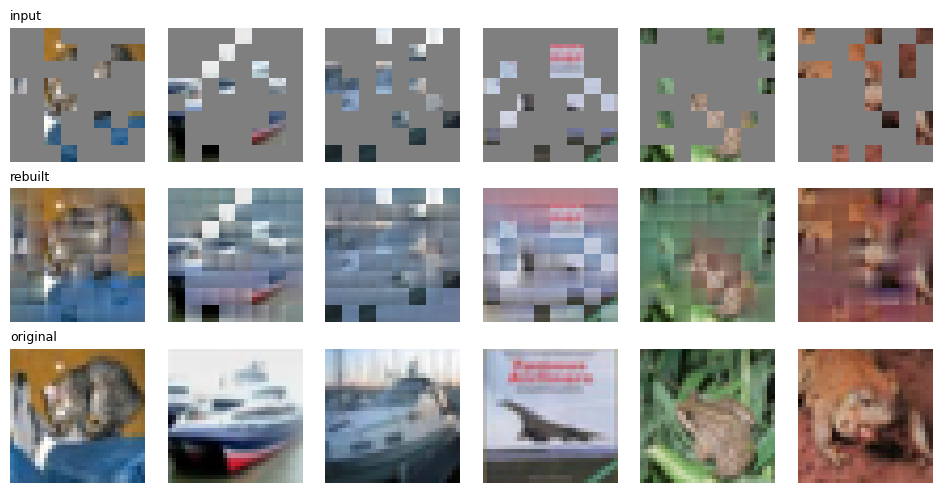

In [ ]:
reference = train_mae()
encoder = reference["mae"].encoder
print("k-NN per encoder block:", [round(knn_eval(encoder, b), 4) for b in range(1, 5)])
print("peak GPU memory, GB:", round(torch.cuda.max_memory_allocated() / 2**30, 1))
show_reconstructions(reference["mae"])

# Your solution

**Part 1:** is the paper's explanation true for the real MAE? **Part 2:** your own MAE, as good as you can make it on `knn_eval()`. Results vanish with the runtime, so save what you need to Drive. Good luck!

12 8 12
mae_enc [25.4, 33.7, 40.4, 42.6, 44.2, 47.9, 51.1, 56.9, 62.5, 69.9, 74.4, 77.5, 79.1]
mae_dec [67.3, 73.0, 75.1, 74.9, 71.5, 66.8, 62.3, 57.1, 54.1]
dino [25.9, 44.2, 51.0, 56.5, 61.9, 67.8, 74.3, 78.8, 82.5, 82.8, 81.5, 81.7, 82.7]


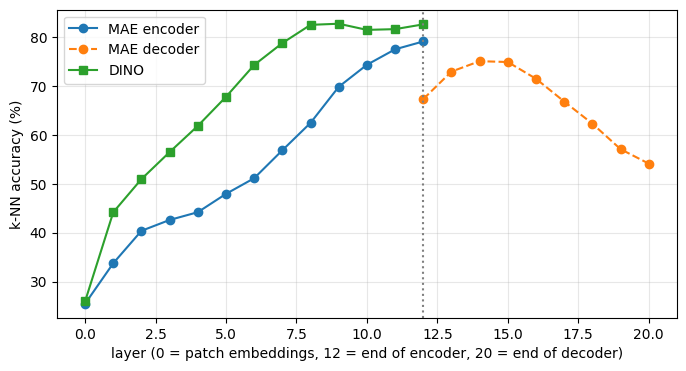

decoder, 75% masked [67.7, 77.8, 79.0, 78.9, 76.1, 71.5, 65.9, 57.7, 52.6]


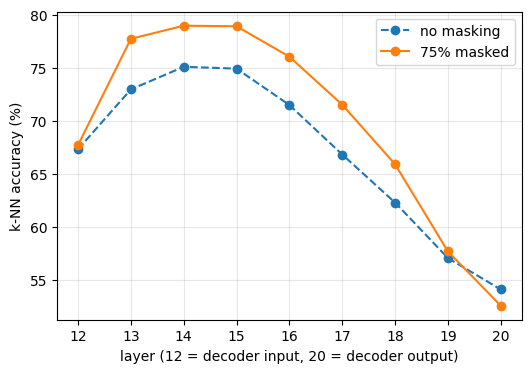

In [ ]:
# Part 1
# %% Part 1: k-NN accuracy after every block (MAE encoder, MAE decoder, DINO)

def get_blocks(model):
    # list of transformer blocks
    return max((m for m in model.modules() if isinstance(m, nn.ModuleList)), key=len)

enc_blocks, dec_blocks, dino_blocks = get_blocks(mae.vit), get_blocks(mae.decoder), get_blocks(dino)
print(len(enc_blocks), len(dec_blocks), len(dino_blocks))   # 12 8 12

def record(blocks, outputs):
    # saves the input of every block and the output of the last one
    hooks = [b.register_forward_pre_hook(lambda m, args: outputs.append(args[0])) for b in blocks]
    hooks.append(blocks[-1].register_forward_hook(
        lambda m, args, out: outputs.append(out[0] if isinstance(out, tuple) else out)))
    return hooks

@torch.no_grad()
def layer_features(images, mask_ratio=0.0, batch_size=128):
    # returns {"mae_enc": (N, 13, 768), "mae_dec": (N, 9, 512), "dino": (N, 13, 768)}
    # feature of a layer = average of its patch tokens
    feats = {"mae_enc": [], "mae_dec": [], "dino": []}
    mae.config.mask_ratio = mask_ratio
    for i in range(0, len(images), batch_size):
        x = to_224(images[i:i + batch_size])
        tokens = {name: [] for name in feats}
        hooks = record(enc_blocks, tokens["mae_enc"]) + record(dec_blocks, tokens["mae_dec"]) \
              + record(dino_blocks, tokens["dino"])
        out = mae.vit(pixel_values=x)
        mae.decoder(out.last_hidden_state, out.ids_restore)
        dino(pixel_values=x)
        for h in hooks:
            h.remove()
        for name in feats:
            feats[name].append(torch.stack([t[:, 1:].float().mean(1) for t in tokens[name]], 1).half())
    mae.config.mask_ratio = 0.0
    return {name: torch.cat(f) for name, f in feats.items()}

def knn_per_layer(train_feats, test_feats):
    # weighted_knn from Step 3 on every layer, accuracy in %
    return [100 * weighted_knn(F.normalize(train_feats[:, l].float(), dim=-1), bank_labels,
                               F.normalize(test_feats[:, l].float(), dim=-1), test_labels)
            for l in range(train_feats.shape[1])]


# %% Features and k-NN (20,000 training images as neighbours, 10,000 test images as queries)
torch.manual_seed(0)
bank = torch.randperm(len(train_images), device=device)[:20000]
bank_labels = train_labels[bank]

train_feats = layer_features(train_images[bank])
test_feats = layer_features(test_images)
acc = {name: knn_per_layer(train_feats[name], test_feats[name]) for name in train_feats}
for name, a in acc.items():
    print(name, [round(v, 1) for v in a])

plt.figure(figsize=(8, 4))
plt.plot(range(13), acc["mae_enc"], "o-", label="MAE encoder")
plt.plot(range(12, 21), acc["mae_dec"], "o--", label="MAE decoder")
plt.plot(range(13), acc["dino"], "s-", label="DINO")
plt.axvline(12, color="gray", ls=":")
plt.xlabel("layer (0 = patch embeddings, 12 = end of encoder, 20 = end of decoder)")
plt.ylabel("k-NN accuracy (%)")
plt.legend(); plt.grid(alpha=.3); plt.show()


# %% Check: decoder with 75% masking, as during pretraining
torch.manual_seed(0)
train_feats_75 = layer_features(train_images[bank], mask_ratio=0.75)
test_feats_75 = layer_features(test_images, mask_ratio=0.75)
acc_dec_75 = knn_per_layer(train_feats_75["mae_dec"], test_feats_75["mae_dec"])
print("decoder, 75% masked", [round(v, 1) for v in acc_dec_75])

plt.figure(figsize=(6, 4))
plt.plot(range(12, 21), acc["mae_dec"], "o--", label="no masking")
plt.plot(range(12, 21), acc_dec_75, "o-", label="75% masked")
plt.xlabel("layer (12 = decoder input, 20 = decoder output)")
plt.ylabel("k-NN accuracy (%)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
# Part 1 (cd.) — zapis na Drive + funkcje pomocnicze dla P1.4, P1.6, P1.7
import os, json
from collections import defaultdict
from google.colab import drive

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/Pattern Recognition/Task_2/results'
os.makedirs(SAVE_DIR, exist_ok=True)

def save_json(obj, name):
    with open(f'{SAVE_DIR}/{name}.json', 'w') as f:
        json.dump(obj, f, indent=1)

def save_fig(name):
    plt.savefig(f'{SAVE_DIR}/{name}.png', dpi=150, bbox_inches='tight')

def decorate(ax, ylabel):
    ax.set_xticks(range(22), [str(l) for l in range(13)] + [f'D{l}' for l in range(9)], fontsize=8)
    ax.axvline(12.5, color='gray', ls=':')
    ax.set_xlabel('layer   (0-12: encoder,  D0-D8: decoder)')
    ax.set_ylabel(ylabel); ax.grid(alpha=.3)

N_PATCHES = 196

def identity_noise(B):
    # HF ViTMAE orders patches by argsort(noise): noise = 0..195 means "no shuffling"
    return torch.arange(N_PATCHES, device=device, dtype=torch.float32).expand(B, -1)

def set_mask_ratio(r):
    mae.config.mask_ratio = r
    mae.vit.embeddings.config.mask_ratio = r

def decoder_hidden_states(latent, ids_restore):
    # runs the normal MAE decoder and records, via hooks:
    # [input of block 1, output of block 1, ..., output of block 8], before the decoder's final LayerNorm
    states, layers = [], mae.decoder.decoder_layers
    def before_first(module, args, kwargs):
        states.append(args[0] if args else kwargs['hidden_states'])
    def after_each(module, args, output):
        states.append(output[0] if isinstance(output, tuple) else output)
    handles = [layers[0].register_forward_pre_hook(before_first, with_kwargs=True)]
    handles += [layer.register_forward_hook(after_each) for layer in layers]
    try:
        mae.decoder(latent, ids_restore)
    finally:
        for h in handles:
            h.remove()
    return states

save_json(dict(acc=acc, acc_dec_75=acc_dec_75), 'part1_knn_per_layer')   # wyniki z komórki kolegi

Mounted at /content/drive


done in 12s
      model  layer    raw  centered  standardized  mean_cos  top1_var  top10_var  eff_rank
0   mae_enc      0  25.45     26.75         28.29     0.933     0.565      0.999     2.747
1   mae_enc      1  33.74     33.94         37.53     0.867     0.609      0.985     3.568
2   mae_enc      2  40.38     39.70         43.50     0.884     0.593      0.964     4.546
3   mae_enc      3  42.60     41.99         45.59     0.864     0.533      0.948     5.832
4   mae_enc      4  44.19     44.18         48.74     0.866     0.519      0.936     6.416
5   mae_enc      5  47.94     49.12         52.94     0.870     0.495      0.901     8.167
6   mae_enc      6  51.15     51.97         56.47     0.859     0.438      0.869    10.509
7   mae_enc      7  56.87     57.58         61.43     0.831     0.388      0.820    14.678
8   mae_enc      8  62.48     63.18         67.06     0.812     0.340      0.763    20.881
9   mae_enc      9  69.86     69.56         73.64     0.807     0.291      0.6

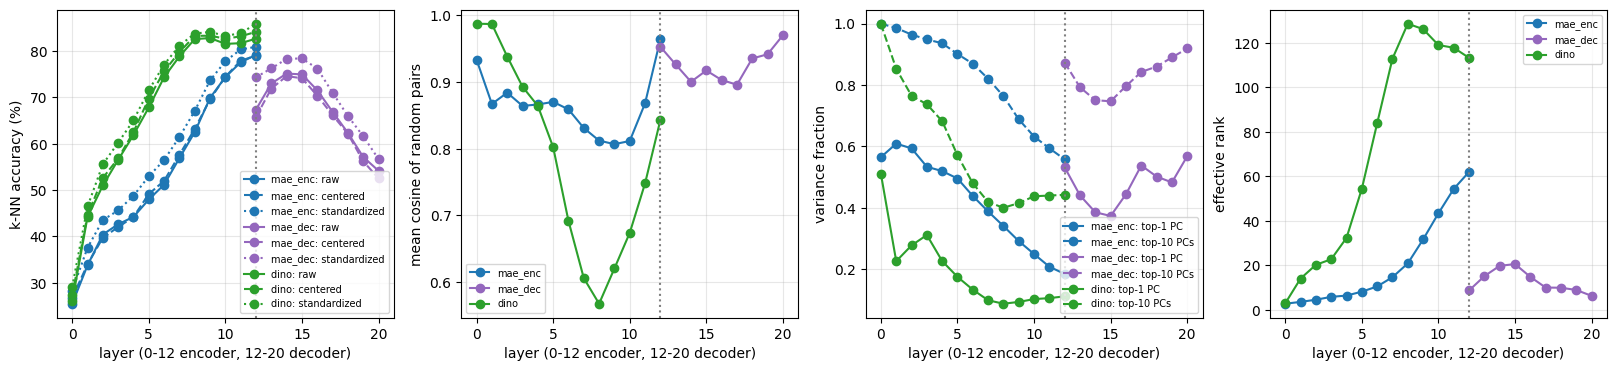

In [ ]:
# P1.4 — feature geometry + k-NN after centering / standardizing (on the features from the cell above)
def knn_layer(tr, te, transform=None):
    # same k-NN and bank as above; statistics for centering/standardizing come from the bank only
    tr, te = tr.float(), te.float()
    if transform is not None:
        mu = tr.mean(0)
        sd = tr.std(0) + 1e-6 if transform == 'standardize' else 1.
        tr, te = (tr - mu) / sd, (te - mu) / sd
    return 100 * weighted_knn(F.normalize(tr, dim=-1), bank_labels, F.normalize(te, dim=-1), test_labels)

@torch.no_grad()
def geometry(f, n=5000):
    X = f[:n].float()
    Xn = F.normalize(X, dim=-1)
    mean_cos = ((Xn @ Xn.T).sum() - n) / (n * (n - 1))        # off-diagonal mean
    v = torch.linalg.svdvals(X - X.mean(0)) ** 2
    v = v / v.sum()                                             # variance fraction per principal component
    eff_rank = torch.exp(-(v * torch.log(v + 1e-12)).sum())
    return dict(mean_cos=mean_cos.item(), top1_var=v[0].item(), top10_var=v[:10].sum().item(), eff_rank=eff_rank.item())

start, rows = time.time(), []
for name in ['mae_enc', 'mae_dec', 'dino']:
    for l in range(train_feats[name].shape[1]):
        tr, te = train_feats[name][:, l], test_feats[name][:, l]
        rows.append(dict(model=name, layer=l, raw=acc[name][l],
                         centered=knn_layer(tr, te, 'center'), standardized=knn_layer(tr, te, 'standardize'),
                         **geometry(tr)))
geo = pd.DataFrame(rows)
save_json(rows, 'part1_geometry')
print(f'done in {time.time() - start:.0f}s')
print(geo.round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for name, color in [('mae_enc', 'C0'), ('mae_dec', 'C4'), ('dino', 'C2')]:
    g = geo[geo.model == name]
    x = g.layer + (12 if name == 'mae_dec' else 0)             # same x-axis as above: decoder at 12..20
    axes[0].plot(x, g.raw, 'o-', c=color, label=f'{name}: raw')
    axes[0].plot(x, g.centered, 'o--', c=color, label=f'{name}: centered')
    axes[0].plot(x, g.standardized, 'o:', c=color, label=f'{name}: standardized')
    axes[1].plot(x, g.mean_cos, 'o-', c=color, label=name)
    axes[2].plot(x, g.top1_var, 'o-', c=color, label=f'{name}: top-1 PC')
    axes[2].plot(x, g.top10_var, 'o--', c=color, label=f'{name}: top-10 PCs')
    axes[3].plot(x, g.eff_rank, 'o-', c=color, label=name)
for ax, ylabel in zip(axes, ['k-NN accuracy (%)', 'mean cosine of random pairs', 'variance fraction', 'effective rank']):
    ax.axvline(12, color='gray', ls=':'); ax.set_xlabel('layer (0-12 encoder, 12-20 decoder)')
    ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.legend(fontsize=7)
save_fig('part1_geometry'); plt.show()

done in 136s


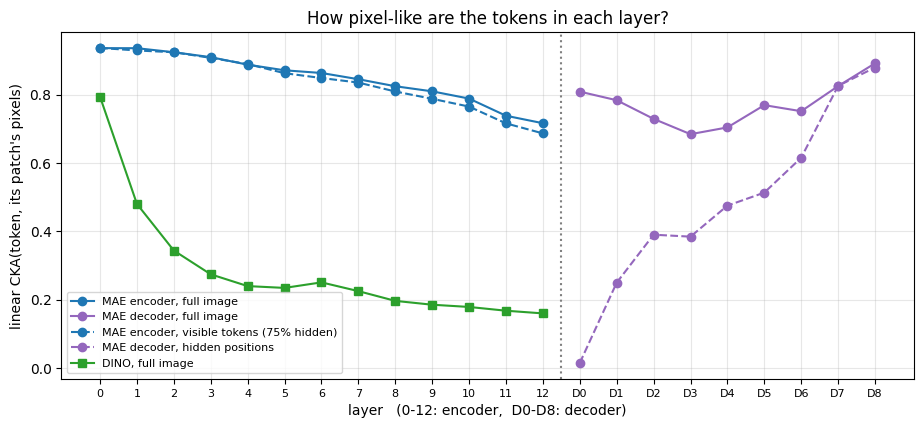

In [ ]:
# P1.6 — token-level linear CKA between each layer and the pixels of the token's own patch
class StreamingCKA:
    # linear CKA between X (M, d) and Y (M, p), accumulated over batches in float64
    def __init__(self):
        self.n, self.s = 0, {}
    def add(self, X, Y):
        X, Y = X.double(), Y.double()
        for k, v in dict(sx=X.sum(0), sy=Y.sum(0), xx=X.T @ X, yy=Y.T @ Y, xy=X.T @ Y).items():
            self.s[k] = self.s.get(k, 0) + v
        self.n += len(X)
    def value(self):
        n, s = self.n, self.s
        cxx = s['xx'] - torch.outer(s['sx'], s['sx']) / n
        cyy = s['yy'] - torch.outer(s['sy'], s['sy']) / n
        cxy = s['xy'] - torch.outer(s['sx'], s['sy']) / n
        return ((cxy ** 2).sum() / ((cxx ** 2).sum().sqrt() * (cyy ** 2).sum().sqrt())).item()

def patchify_224(x):
    # (B, 3, 224, 224) -> (B, 196, 768), row-major 14x14 grid, the same order as the ViT tokens
    return x.unfold(2, 16, 16).unfold(3, 16, 16).permute(0, 2, 3, 1, 4, 5).reshape(len(x), 196, 768)

def flat(t):
    return t.reshape(-1, t.shape[-1])

@torch.no_grad()
def cka_profile(n_images=1000, bs=50, seed=0):
    acc_cka = defaultdict(StreamingCKA)
    g = torch.Generator(device=device).manual_seed(seed)
    try:
        for i in range(0, n_images, bs):
            x = to_224(test_images[i:i + bs])
            Y = patchify_224(x.float())                                       # (B, 196, 768) pixels per patch
            # full image: MAE encoder, MAE decoder, DINO (tokens are in image order thanks to identity noise)
            set_mask_ratio(0.0)
            out = mae.vit(pixel_values=x, noise=identity_noise(len(x)), output_hidden_states=True)
            for l, h in enumerate(out.hidden_states):
                acc_cka[f'mae/enc{l}'].add(flat(h[:, 1:]), flat(Y))
            dec = decoder_hidden_states(out.last_hidden_state, out.ids_restore)
            for l, h in enumerate(dec):
                acc_cka[f'mae/dec{l}'].add(flat(h[:, 1:]), flat(Y))
            out = dino(pixel_values=x, output_hidden_states=True)
            for l, h in enumerate(out.hidden_states):
                acc_cka[f'dino/enc{l}'].add(flat(h[:, 1:]), flat(Y))
            # training regime: 75% hidden
            set_mask_ratio(.75)
            noise = torch.rand(len(x), N_PATCHES, device=device, generator=g)
            keep = noise.argsort(1)[:, :49]                                   # the same rule HF uses to pick visible patches
            Y_keep = Y.gather(1, keep[..., None].expand(-1, -1, 768))
            out = mae.vit(pixel_values=x, noise=noise, output_hidden_states=True)
            for l, h in enumerate(out.hidden_states):                         # visible tokens vs their own pixels
                acc_cka[f'mae_masked/enc{l}'].add(flat(h[:, 1:]), flat(Y_keep))
            hidden = out.mask.bool()                                          # (B, 196), True = hidden patch
            dec = decoder_hidden_states(out.last_hidden_state, out.ids_restore)
            for l, h in enumerate(dec):                                       # hidden positions only
                acc_cka[f'mae_masked/dec{l}'].add(h[:, 1:][hidden], Y[hidden])
    finally:
        set_mask_ratio(0.0)
    return {k: a.value() for k, a in acc_cka.items()}

start = time.time()
cka = cka_profile()
save_json(cka, 'part1_cka_with_pixels')
print(f'done in {time.time() - start:.0f}s')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(range(13), [cka[f'mae/enc{l}'] for l in range(13)], 'o-', c='C0', label='MAE encoder, full image')
ax.plot(range(13, 22), [cka[f'mae/dec{l}'] for l in range(9)], 'o-', c='C4', label='MAE decoder, full image')
ax.plot(range(13), [cka[f'mae_masked/enc{l}'] for l in range(13)], 'o--', c='C0', label='MAE encoder, visible tokens (75% hidden)')
ax.plot(range(13, 22), [cka[f'mae_masked/dec{l}'] for l in range(9)], 'o--', c='C4', label='MAE decoder, hidden positions')
ax.plot(range(13), [cka[f'dino/enc{l}'] for l in range(13)], 's-', c='C2', label='DINO, full image')
decorate(ax, "linear CKA(token, its patch's pixels)"); ax.legend(fontsize=8)
ax.set_title('How pixel-like are the tokens in each layer?')
save_fig('part1_cka_pixels'); plt.show()

In [ ]:
# Part 2